# 17 CT 图像预处理与分割入门

学习 DICOM 像素值到 HU、窗宽窗位、掩膜对齐、阈值基线和 Dice 指标。
**默认输入是程序生成的合成 HU 切片和合成肿瘤掩膜，不是病人影像，不训练或验证临床模型。**
这样没有医学数据下载、隐私或 GPU 门槛；另提供读取自己有权使用的 DICOM 文件的入口。


In [1]:
from pathlib import Path
import sys, os
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "course_utils.py").exists():
        sys.path.insert(0, str(folder)); break
else:
    raise FileNotFoundError("请从课程项目根目录或 notebooks 目录启动 Jupyter。")
from course_utils import setup, device, save_figure
ROOT = setup(seed=42)
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
from torch import nn
torch.set_num_threads(min(2, os.cpu_count() or 1))
DEVICE = device()
print("计算设备：", DEVICE)


计算设备： cpu


## 1. 合成有明确真值的 CT 切片

设定空气约 −1000 HU、脂肪约 −100 HU、软组织约 40 HU，并构造一个低密度椭圆病灶。
真实 CT 的组织值会随设备、增强期相和病情变化；这些数值只是教学参数，不是诊断阈值。

`hu` 是 `[H,W]=[128,128]` 的二维浮点矩阵：一行对应图像一行、每列对应一个像素，数值表示 HU，而不是 0–255 的屏幕亮度。
例如本例的 `−1000`、`35`、`75` 分别模拟空气、软组织和肝脏区域，加入噪声后会在相应数值附近波动。
同尺寸的 `truth` 是布尔矩阵，`True/1` 表示合成病灶、`False/0` 表示其余位置；它与 HU 矩阵逐像素对齐。


HU 矩阵片段：
 [[16.4 14.7 10.6 13.3 18.7 19.7]
 [19.7 21.2 16.4 10.8 16.  16.3]
 [10.8 18.1 17.6 24.8 19.8 29. ]
 [10.3 20.7 15.2 17.1 22.4 27.1]
 [13.1 13.1 23.1 20.  17.6 18.1]
 [25.8 22.9 25.7 27.8 16.1 27.5]]
掩膜片段：
 [[1 1 1 1 1 1]
 [1 1 1 1 1 1]
 [1 1 1 1 1 1]
 [1 1 1 1 1 1]
 [1 1 1 1 1 1]
 [1 1 1 1 1 1]]


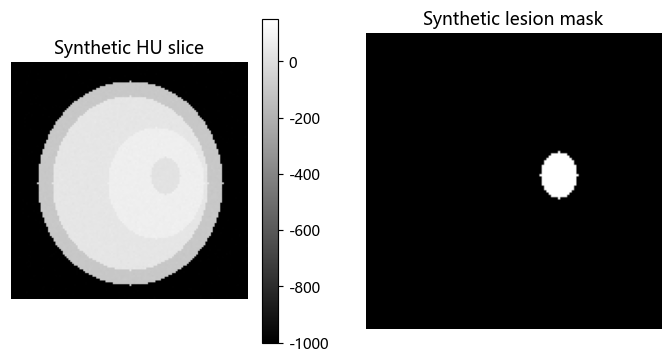

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/17_ct_inputs.png')

In [2]:
rng=np.random.default_rng(42)
H=W=128
yy,xx=np.mgrid[:H,:W]
body=((xx-64)/50)**2+((yy-65)/55)**2<=1
liver=((xx-78)/26)**2+((yy-65)/30)**2<=1
tumor=((xx-83)/8)**2+((yy-61)/10)**2<=1
hu=np.full((H,W),-1000.,np.float32)
hu[body]=-100.; hu[((xx-64)/42)**2+((yy-65)/47)**2<=1]=35.
hu[liver]=75.; hu[tumor]=20.
hu+=rng.normal(0,5,hu.shape).astype(np.float32)
truth=tumor.astype(bool)
print("HU 矩阵片段：\n",np.round(hu[57:63,79:85],1))
print("掩膜片段：\n",truth[57:63,79:85].astype(int))
fig,axs=plt.subplots(1,2,figsize=(8,4))
im=axs[0].imshow(hu,cmap="gray",vmin=-1000,vmax=150); axs[0].set_title("Synthetic HU slice"); plt.colorbar(im,ax=axs[0])
axs[1].imshow(truth,cmap="gray"); axs[1].set_title("Synthetic lesion mask")
for ax in axs: ax.axis("off")
save_figure("17_ct_inputs.png")


## 2. 模拟存储值与 HU 的线性变换

对常见 CT 对象，`HU = StoredValue × RescaleSlope + RescaleIntercept`。实际文件还需检查 Modality、单位和相关元数据。
不能把任意图像数组都宣称为 HU。这里用已知参数把合成 HU 转成存储值，再验证逆变换。


In [3]:
slope,intercept=1.,-1024.
stored=np.rint((hu-intercept)/slope).astype(np.int16)
recovered=stored.astype(np.float32)*slope+intercept
print("存储值局部：\n",stored[57:61,79:83])
print("恢复 HU 局部：\n",recovered[57:61,79:83])
print("量化最大误差：",np.abs(recovered-hu).max())
assert np.abs(recovered-hu).max()<=.51


存储值局部：
 [[1040 1039 1035 1037]
 [1044 1045 1040 1035]
 [1035 1042 1042 1049]
 [1034 1045 1039 1041]]
恢复 HU 局部：
 [[16. 15. 11. 13.]
 [20. 21. 16. 11.]
 [11. 18. 18. 25.]
 [10. 21. 15. 17.]]
量化最大误差： 0.5000496


## 3. 窗宽窗位只影响显示映射

教学线性显示：先裁剪到 `[中心−宽度/2,中心+宽度/2]`，再映射到 0–1。
这不是完整的 DICOM VOI LUT 标准实现；读取真实文件时应使用 `apply_voi_lut` 等标准处理并检查窗参数。
显示窗改变不应覆盖原始 HU，也不能让掩膜随显示窗改变。

例如 `center=60,width=150` 时，窗口下限是 `−15 HU`、上限是 `135 HU`：小于等于 −15 显示为 0（黑），大于等于 135 显示为 1（白），60 HU 映射为 0.5（中灰）。
20 HU 会映射为 `(20−(−15))/150≈0.233`。映射后的显示矩阵仍是 `[128,128]`，但其单位已经是 0–1 的显示强度；后续分割仍使用原始 HU 矩阵。


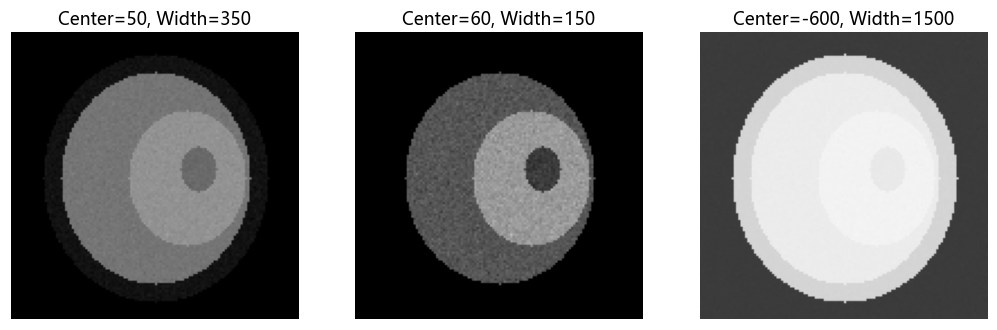

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/17_ct_windows.png')

In [4]:
def window_image(hu_image,center,width):
    if width<=0: raise ValueError("窗宽必须大于 0")
    return np.clip((hu_image-(center-width/2))/width,0,1)
windows=[(50,350),(60,150),(-600,1500)]
fig,axs=plt.subplots(1,3,figsize=(12,4))
for ax,(center,width) in zip(axs,windows):
    ax.imshow(window_image(recovered,center,width),cmap="gray",vmin=0,vmax=1)
    ax.set_title(f"Center={center}, Width={width}"); ax.axis("off")
save_figure("17_ct_windows.png")


## 4. 最简单的 ROI 阈值分割基线

本例已知合成肝脏区域，先用 ROI 限制，再对低 HU 区域阈值分割。真实医学图像通常没有这样的现成 ROI，不能把本实验分数等同于自动临床肝肿瘤分割。
对真实深度学习分割，需要独立病人划分、像素/体素空间对齐、训练与外部验证；第 08 课演示网络训练流程。


合成切片 Dice=1.000, IoU=1.000
输入/预测/真值的形状： (128, 128) (128, 128) (128, 128)


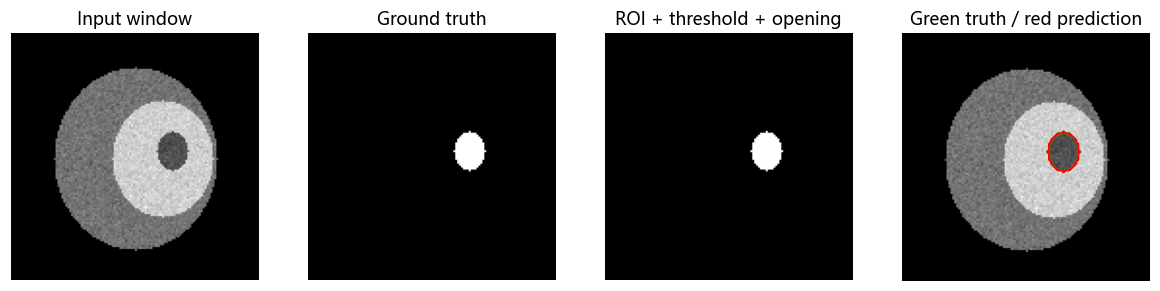

In [5]:
raw_pred=liver & (recovered<38)
kernel=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(3,3))
pred=cv2.morphologyEx(raw_pred.astype(np.uint8),cv2.MORPH_OPEN,kernel).astype(bool)
def overlap_metrics(pred,true):
    intersection=np.logical_and(pred,true).sum()
    dice=2*intersection/max(pred.sum()+true.sum(),1)
    iou=intersection/max(np.logical_or(pred,true).sum(),1)
    return dice,iou
dice,iou=overlap_metrics(pred,truth)
print(f"合成切片 Dice={dice:.3f}, IoU={iou:.3f}")
print("输入/预测/真值的形状：",recovered.shape,pred.shape,truth.shape)
fig,axs=plt.subplots(1,4,figsize=(14,4))
axs[0].imshow(window_image(recovered,60,150),cmap="gray"); axs[0].set_title("Input window")
axs[1].imshow(truth,cmap="gray"); axs[1].set_title("Ground truth")
axs[2].imshow(pred,cmap="gray"); axs[2].set_title("ROI + threshold + opening")
axs[3].imshow(window_image(recovered,60,150),cmap="gray")
axs[3].contour(truth,levels=[.5],colors="lime"); axs[3].contour(pred,levels=[.5],colors="red"); axs[3].set_title("Green truth / red prediction")
for ax in axs: ax.axis("off")
save_figure("17_ct_segmentation.png")
assert dice>.9,"合成基线与真值不一致，请检查坐标和阈值。"


## 5. 故意制造掩膜错位

相同大小不代表空间对齐。真实 DICOM 还涉及切片顺序、方向、原点、PixelSpacing 与层间距离。
把标签平移几像素，Dice 就会下降；可视化叠加能发现单纯检查 shape 发现不了的问题。


正确对齐 Dice=1.000；错位 7 像素 Dice=0.449


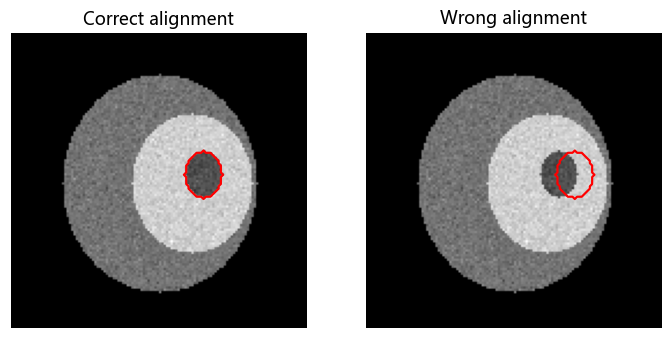

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/17_ct_alignment.png')

In [6]:
shifted_truth=np.roll(truth,7,axis=1)
bad_dice,_=overlap_metrics(pred,shifted_truth)
print(f"正确对齐 Dice={dice:.3f}；错位 7 像素 Dice={bad_dice:.3f}")
fig,axs=plt.subplots(1,2,figsize=(8,4))
for ax,mask,title in zip(axs,[truth,shifted_truth],["Correct alignment","Wrong alignment"]):
    ax.imshow(window_image(recovered,60,150),cmap="gray"); ax.contour(mask,levels=[.5],colors="red"); ax.set_title(title); ax.axis("off")
save_figure("17_ct_alignment.png")


## 6. 可选：读取自己的单张 CT DICOM

默认不执行、不额外安装依赖。只有设置 `CV_DICOM_PATH` 后才读取；你需要有使用该数据的权限。
如需启用，先安装 `pydicom`（用于解析 DICOM，不用于模型训练）。压缩像素可能还需要对应解码插件。
不要把患者姓名、标识、出生日期或完整原始文件提交到 GitHub。


In [7]:
dicom_path=os.environ.get("CV_DICOM_PATH")
if dicom_path:
    try:
        import pydicom
        from pydicom.pixels import apply_modality_lut
    except ImportError as exc:
        raise ImportError("真实 DICOM 入口需要 pydicom；按 README 的可选依赖说明安装。") from exc
    ds=pydicom.dcmread(dicom_path)
    if getattr(ds,"Modality",None)!="CT": raise ValueError("本入口仅接受 CT，不能假定其他影像单位为 HU。")
    pixels=ds.pixel_array
    if pixels.ndim!=2: raise ValueError("本入口仅示范单帧 2D CT；多帧/体数据需显式处理。")
    real_hu=apply_modality_lut(pixels,ds).astype(np.float32)
    print("读取单帧 CT：",real_hu.shape,"；请核查 RescaleType/单位、方向与 spacing。")
    plt.figure(figsize=(5,5)); plt.imshow(window_image(real_hu,50,350),cmap="gray"); plt.axis("off")
    save_figure("17_optional_ct_window.png")
else:
    print("未设置 CV_DICOM_PATH：继续使用明确标注的合成教学切片。")


未设置 CV_DICOM_PATH：继续使用明确标注的合成教学切片。


## 7. 练习与参考

练习：改变噪声、病灶 HU 和阈值，记录 Dice；用合成切片训练第 08 课网络；按病人而非切片划分真实数据；分别统计肝脏和肿瘤而非只统计整体准确率。

来源：[pydicom modality LUT](https://pydicom.github.io/pydicom/stable/reference/generated/pydicom.pixels.apply_modality_lut.html)、[pydicom VOI LUT](https://pydicom.github.io/pydicom/stable/reference/generated/pydicom.pixels.apply_voi_lut.html)、[nnU-Net 原项目](https://github.com/MIC-DKFZ/nnUNet)。本课不声称复现 nnU-Net 或提供临床建议。
